# PlacementIQ AI - Feature Engineering & EDA
In this notebook, we visualize the target distribution, engineer composite features, encode categoricals, and plot the correlation heatmap.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, MinMaxScaler


## 1. Load Cleaned Data


In [2]:
df = pd.read_csv('dataset/cleaned_train.csv')
df.head()


,Age,Gender,Degree,Branch,CGPA,Internships,Projects,Coding_Skills,Communication_Skills,Aptitude_Test_Score,Soft_Skills_Rating,Certifications,Backlogs,Placement_Status
0,22.0,Female,B.Tech,ECE,6.29,0.0,3.0,4.0,6.0,51.0,5.0,1.0,3.0,Not Placed
1,20.0,Female,BCA,ECE,6.05,1.0,4.0,6.0,8.0,59.0,7.5,2.0,1.0,Not Placed
2,22.0,Male,MCA,ME,7.22,1.0,4.0,6.0,6.0,58.0,6.0,2.0,2.0,Not Placed
3,22.0,Male,MCA,ME,7.78,2.0,4.0,6.0,6.0,90.0,4.0,2.0,0.0,Placed
4,20.0,Female,B.Tech,ME,7.63,1.0,4.0,6.0,5.0,79.0,6.0,2.0,0.0,Placed


## 2. Target Class Distribution


C:\Users\Pansh\AppData\Local\Temp\ipykernel_7956\1940341628.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='Placement_Status', palette=['#2ecc71', '#e74c3c'])


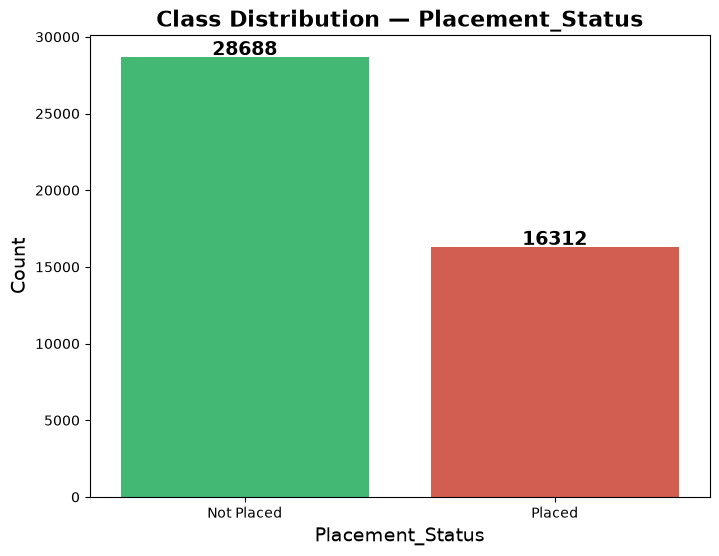

In [3]:
plt.figure(figsize=(8, 6))
ax = sns.countplot(data=df, x='Placement_Status', palette=['#2ecc71', '#e74c3c'])
plt.title('Class Distribution — Placement_Status', fontsize=16, fontweight='bold')
plt.ylabel('Count', fontsize=14)
plt.xlabel('Placement_Status', fontsize=14)
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', fontsize=14, color='black', xytext=(0, 5), textcoords='offset points', fontweight='bold')
plt.savefig('outputs/class_distribution.png', bbox_inches='tight')
plt.show()


## 3. Feature Engineering


In [4]:
df['AcademicScore'] = (df['CGPA'] / 10.0) * 0.6 - (df['Backlogs'] / 5.0) * 0.4
df['TechnicalScore'] = (df['Coding_Skills'] + df['Projects'] + (df['Aptitude_Test_Score']/10.0)) / 30.0
print('Engineered composite scores successfully.')


Engineered composite scores successfully.


## 4. Categorical Encoding


In [5]:
le = LabelEncoder()
cat_cols = df.select_dtypes(include=['object']).columns
for col in cat_cols:
    if col != 'Placement_Status':
        df[col] = le.fit_transform(df[col])

# Map target
df['Placement_Status'] = df['Placement_Status'].map({'Placed': 1, 'Not Placed': 0})


C:\Users\Pansh\AppData\Local\Temp\ipykernel_7956\2421758946.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=['object']).columns


## 5. Feature Correlation Heatmap


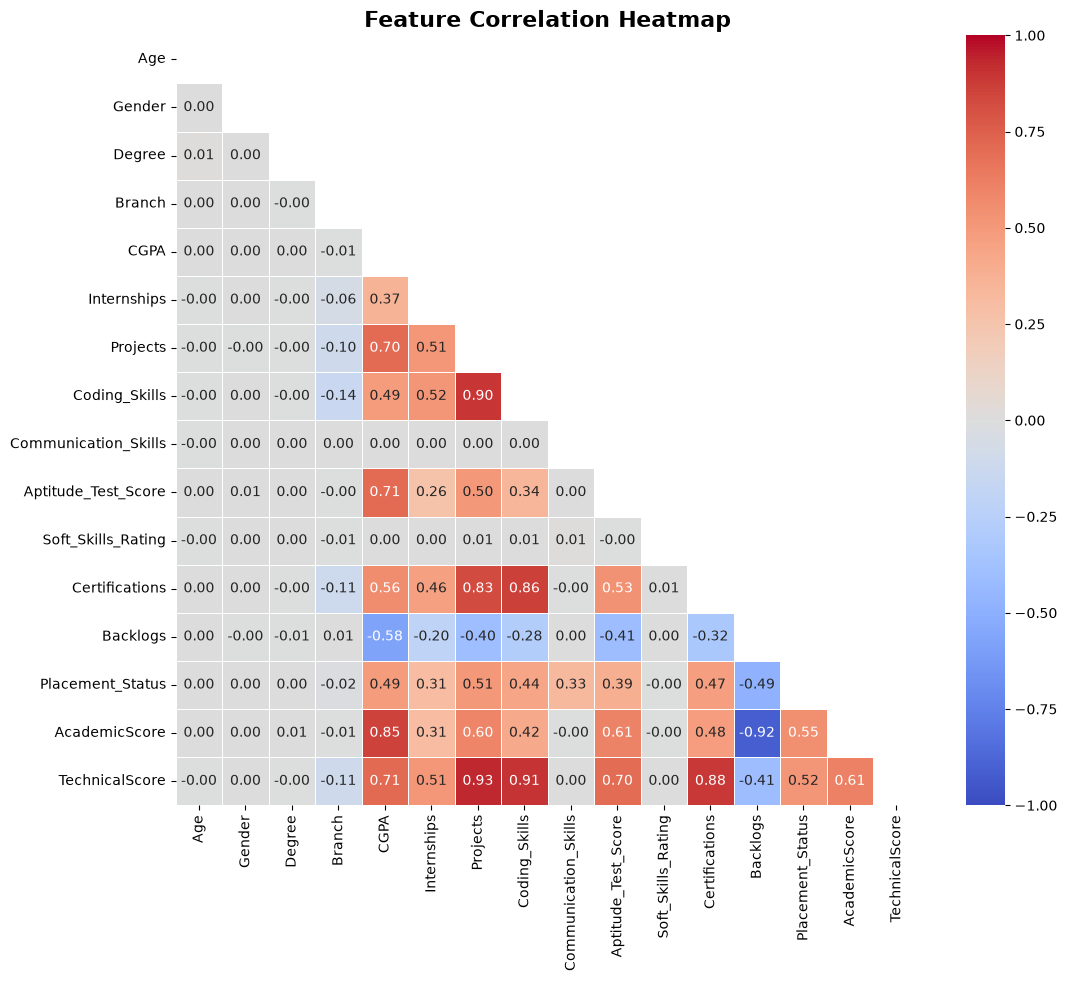

In [6]:
plt.figure(figsize=(12, 10))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Feature Correlation Heatmap', fontsize=16, fontweight='bold')
plt.savefig('outputs/correlation_heatmap.png', bbox_inches='tight')
plt.show()
